# 4. Did any of it hold up?

Segments and product pairs are only useful if they say something about the future. So this notebook hides the last 90 days, builds everything from the earlier sales, and then looks at what those same customers and products did next.

The first version of this project stopped at describing the past.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
from retail_analysis.clean import SHOPS, load, clean, open_shop
from retail_analysis.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, ["#7fb4d8", JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
from retail_analysis.forward import groups_next, pairs_next, over_time, split

before, after, cutoff = split(sales)
print(f"Built from sales up to {cutoff:%B %d, %Y}: {before.customer.nunique():,} customers")
print(f"Checked against the {after.when.dt.date.nunique()} trading days after it")

Built from sales up to September 11, 2011: 3,363 customers
Checked against the 78 trading days after it


## Did the customer segments predict who came back?

In [2]:
table = groups_next(sales)
table.style.format({"customers": "{:,.0f}", "came_back": "{:.0%}", "average_spend_after": "£{:,.0f}"})

,customers,came_back,average_spend_after
group,,,
Big spenders,149,99%,"£7,784"
Best customers,744,81%,£816
Regulars,676,64%,£520
New,237,45%,£259
Occasional,212,45%,£323
Going quiet,449,51%,£359
Lost,896,34%,£185
Everyone,"3,363",57%,£766


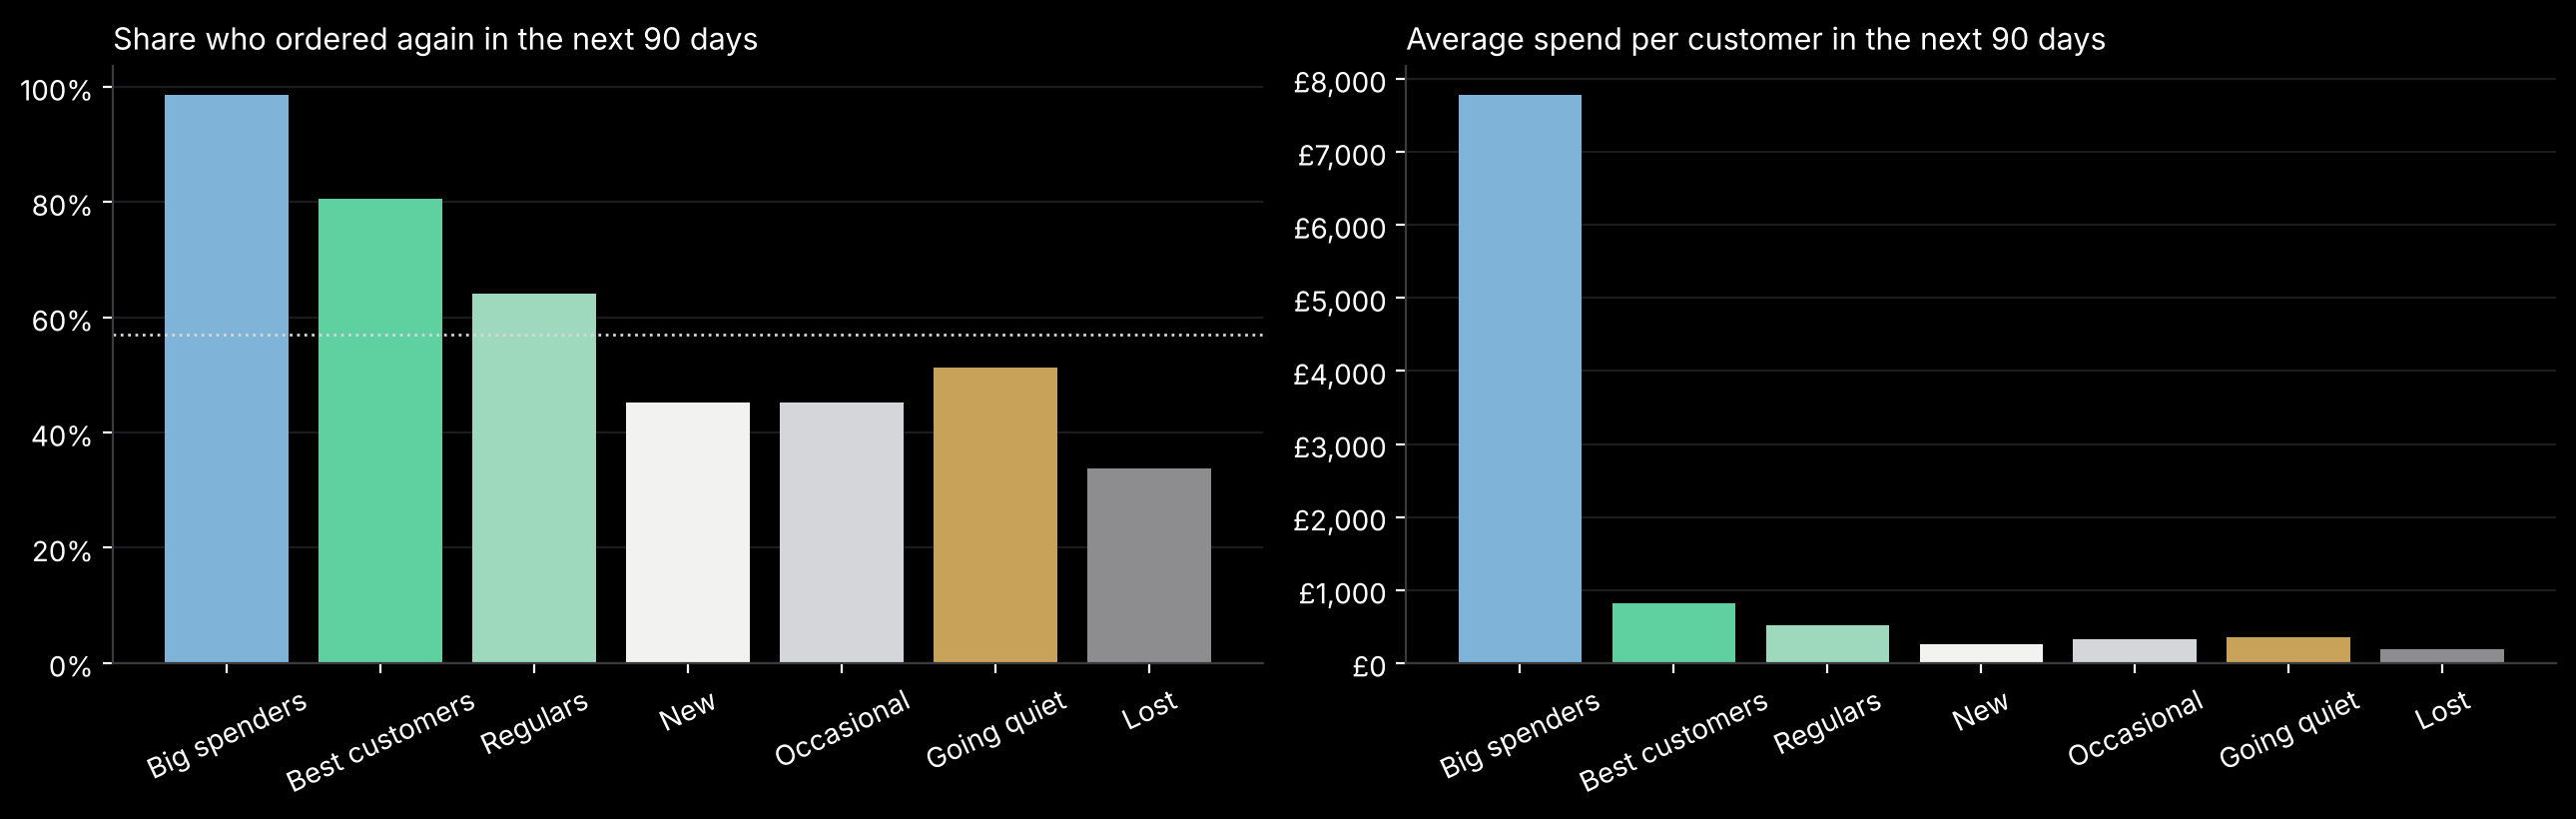

In [3]:
groups = table.drop("Everyone")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(groups.index, groups.came_back, color=[COLORS[g] for g in groups.index])
axes[0].axhline(table.loc["Everyone", "came_back"], color=SILVER, lw=1, ls=":"); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_title("Share who ordered again in the next 90 days", loc="left", fontsize=11)
axes[1].bar(groups.index, groups.average_spend_after, color=[COLORS[g] for g in groups.index]); axes[1].yaxis.set_major_formatter(money)
axes[1].set_title("Average spend per customer in the next 90 days", loc="left", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", rotation=25); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The dotted line is the rate for all customers. The order of the bars is the test: if the segments meant nothing, they would all sit near that line.

## Did the market basket pairs keep selling together?

The 50 strongest pairs from the earlier sales, measured again on the later ones.

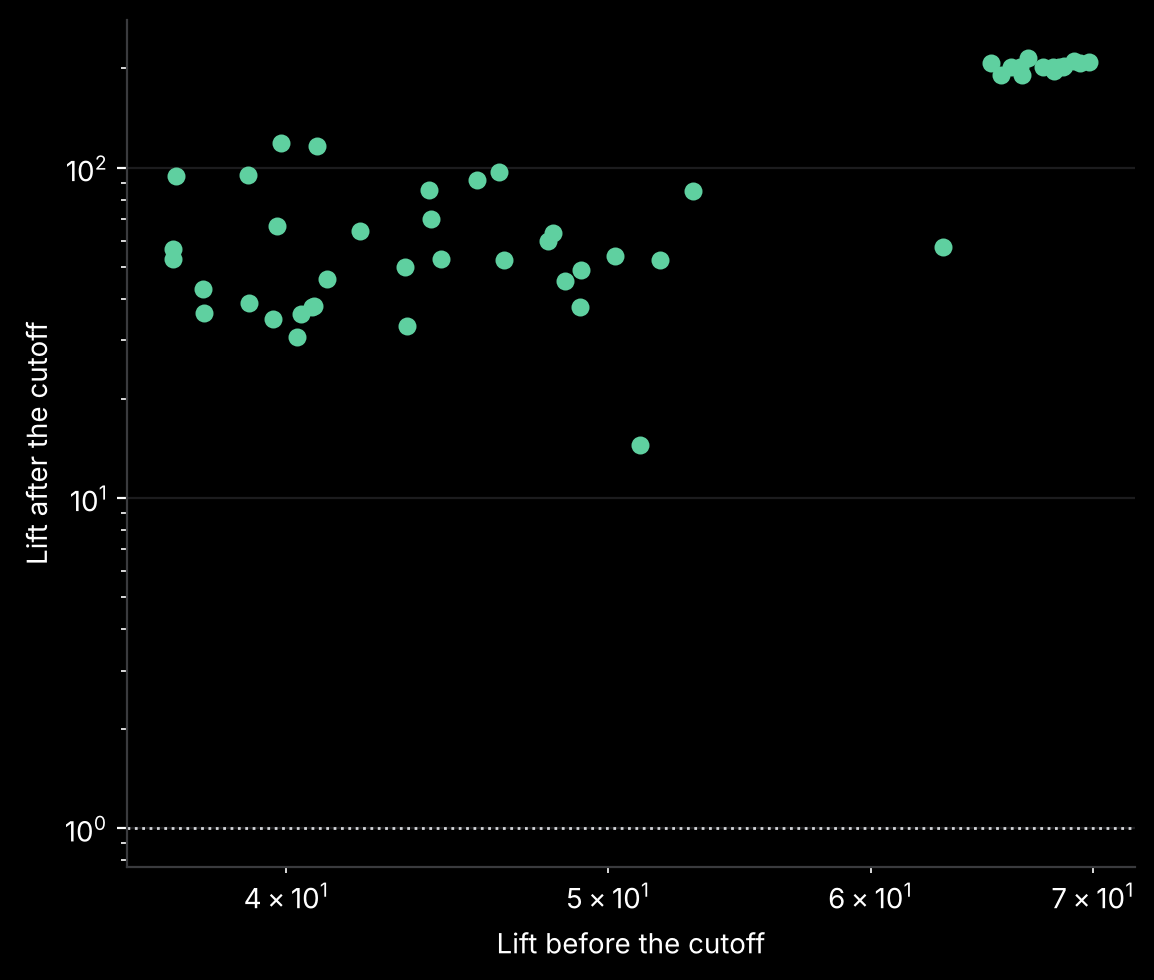

Pairs still bought together more than chance afterward: 50 of 50


In [4]:
checked = pairs_next(sales)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(checked.lift, checked.lift_after.clip(lower=0.5), color=JADE, s=30)
ax.axhline(1, color=SILVER, lw=1, ls=":"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Lift before the cutoff"); ax.set_ylabel("Lift after the cutoff")
plt.show()
print(f"Pairs still bought together more than chance afterward: {(checked.lift_after > 1).sum()} of {len(checked)}")

## Was that one lucky window?

The 90 days above run from September into December, the busiest part of this shop's year. So the whole check is repeated at earlier cutoff days, each one 90 days before the last. A cutoff is used only if at least 90 days of sales come before it.

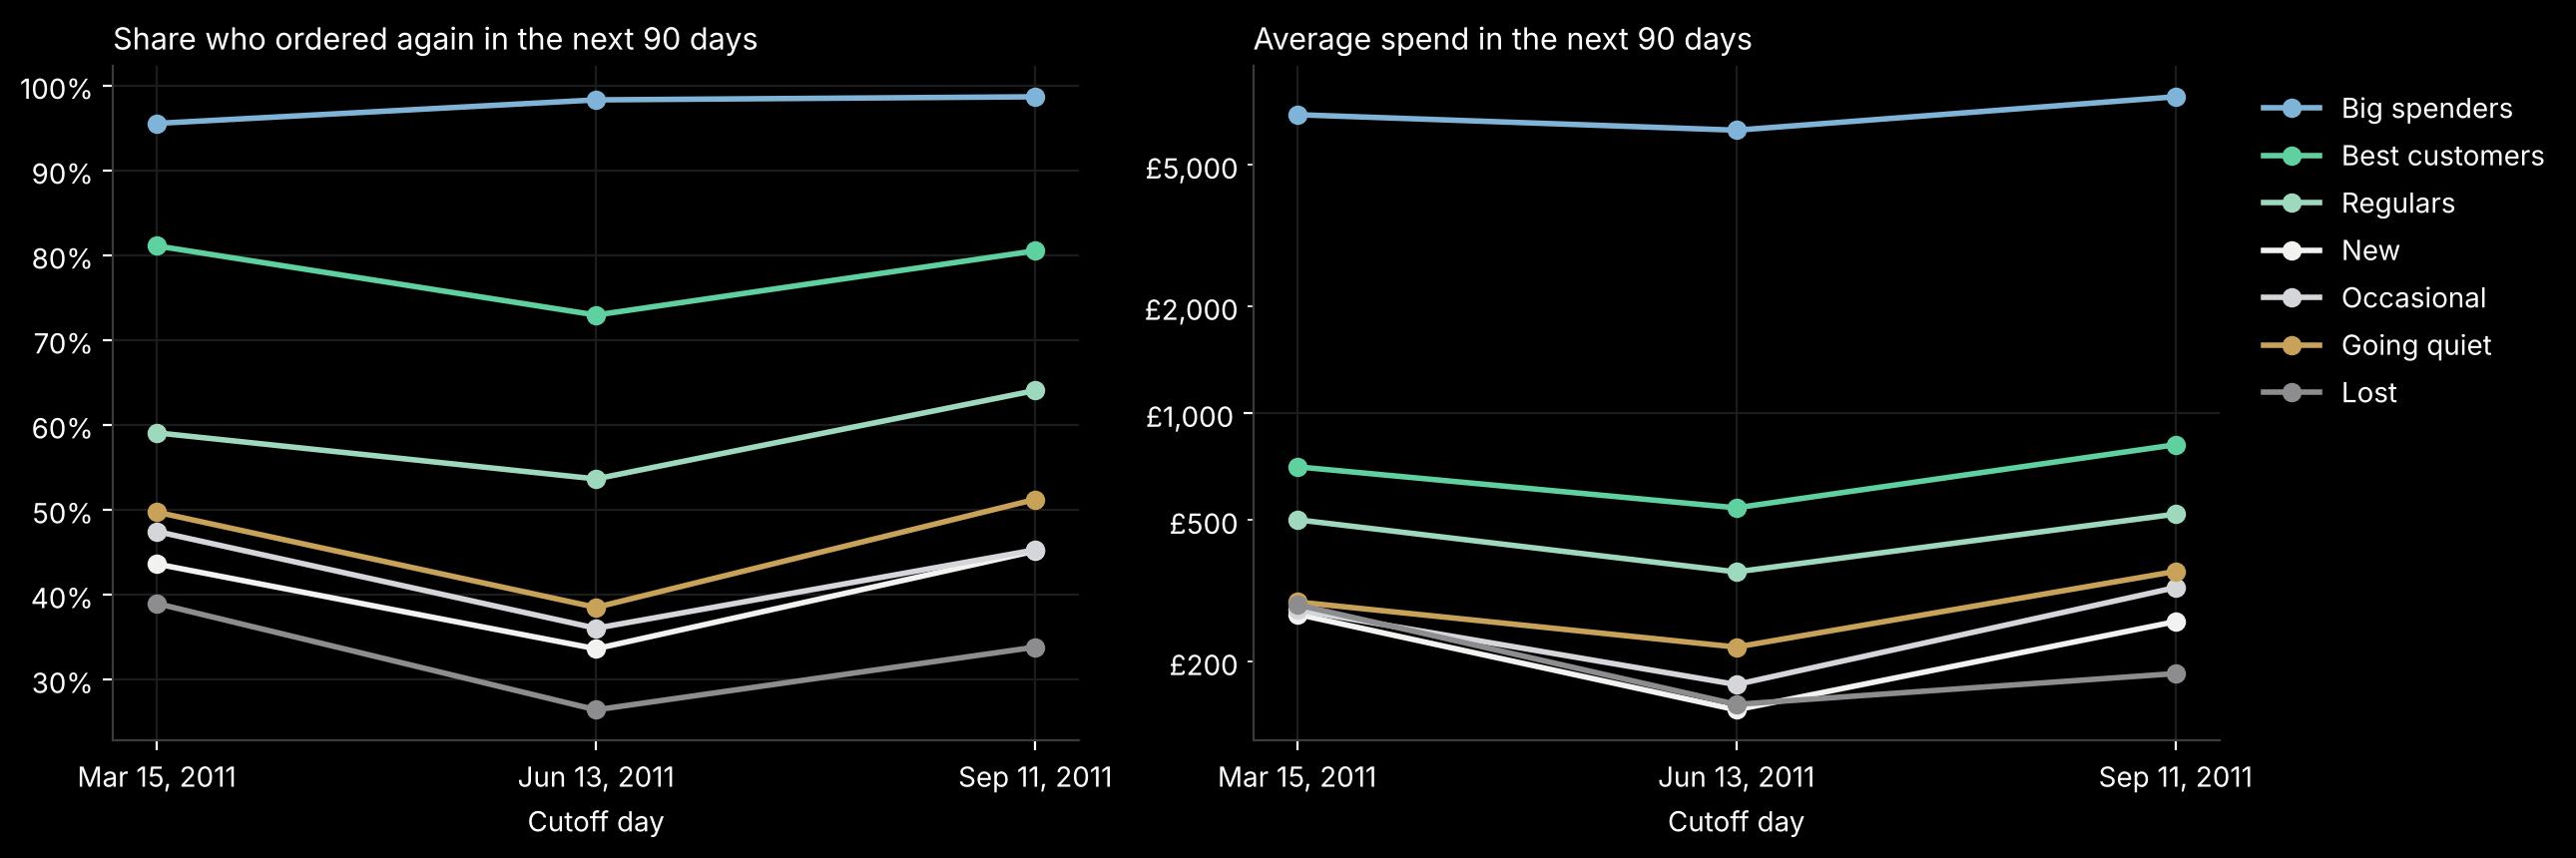

group,Big spenders,Best customers,Regulars,New,Occasional,Going quiet,Lost,Everyone,Pairs still linked
cutoff,,,,,,,,,
"Mar 15, 2011",96%,81%,59%,44%,47%,50%,39%,56%,100%
"Jun 13, 2011",98%,73%,54%,34%,36%,38%,26%,48%,90%
"Sep 11, 2011",99%,81%,64%,45%,45%,51%,34%,57%,100%


In [5]:
checks = over_time(sales)
rate = checks.pivot(index="cutoff", columns="group", values="came_back")
spend = checks.pivot(index="cutoff", columns="group", values="average_spend_after")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, table, title in [(axes[0], rate, "Share who ordered again in the next 90 days"), (axes[1], spend, "Average spend in the next 90 days")]:
    for g in GROUPS:
        ax.plot(table.index.strftime("%b %d, %Y"), table[g], color=COLORS[g], marker="o", lw=2, label=g)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel("Cutoff day")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axes[1].set_yscale("log"); axes[1].yaxis.set_minor_locator(LogLocator(subs=[2, 5]))
axes[1].yaxis.set_major_formatter(money); axes[1].yaxis.set_minor_formatter(money)
axes[1].legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()
rate.reindex(columns=GROUPS + ["Everyone", "Pairs"]).rename(columns={"Pairs": "Pairs still linked"}).rename(index=lambda d: f"{d:%b %d, %Y}").style.format("{:.0%}")

The lines never cross at the top: Big spenders, then Best customers, then Regulars, at every cutoff. The summer window is the quiet one. Fewer customers of every kind came back, and 45 of the 50 strongest pairs stayed linked instead of all 50. The order of the segments still held.

The three weakest segments, New, Occasional and Lost, sit close together and trade places. The earliest cutoff has only about three months of sales behind it, so its segments are rougher.

## What this says

* **The segments predicted behavior.** Nearly every Big spender came back, and they spent about £7,800 each. Best customers came back at 81 percent, Regulars at 64, Lost at 34.
* **It was not one lucky window.** The same order held at three cutoff days, including the quiet summer.
* **Going quiet is a real warning, and not a lost cause.** Around half of them still came back in the busy season, and 38 percent in the quiet one.
* **New customers are a coin flip at best.** Under half ordered again. The second order is where a shop wins or loses them.
* **The strongest pairs kept selling together**: all 50 in two windows and 45 of 50 in the third.